## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

## Load Data

In [2]:
data = pd.read_csv("reduced.csv")
features = ["price", "age", "mileage", "tax", "mpg", "engineSize"]

## Scale Features

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data[features])

## K-Means: Elbow and Silhouette

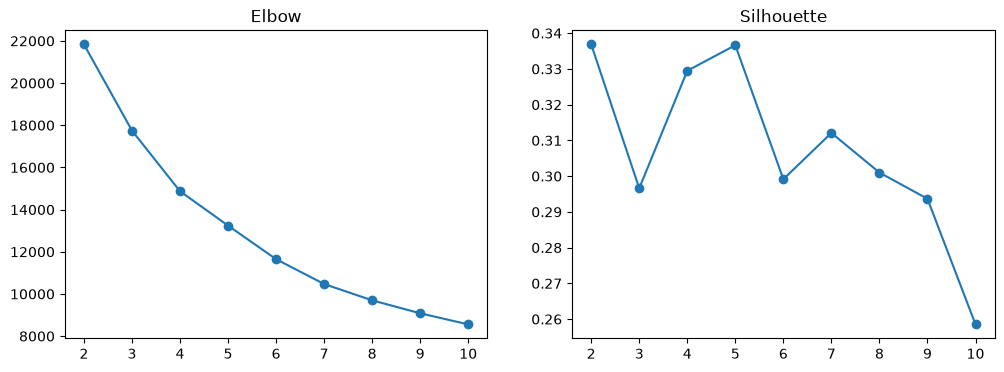

In [4]:
inertia, sil = [], []
k_range = range(2, 11)
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(k_range, inertia, marker="o")
ax[0].set_title("Elbow")
ax[1].plot(k_range, sil, marker="o")
ax[1].set_title("Silhouette")
plt.show()

## K-Means Model

In [5]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
data["KMeans"] = kmeans.fit_predict(X_scaled)
data["KMeans"].value_counts()

KMeans
0    2485
1    1133
2     888
3     494
Name: count, dtype: int64

## Hierarchical: Dendrogram

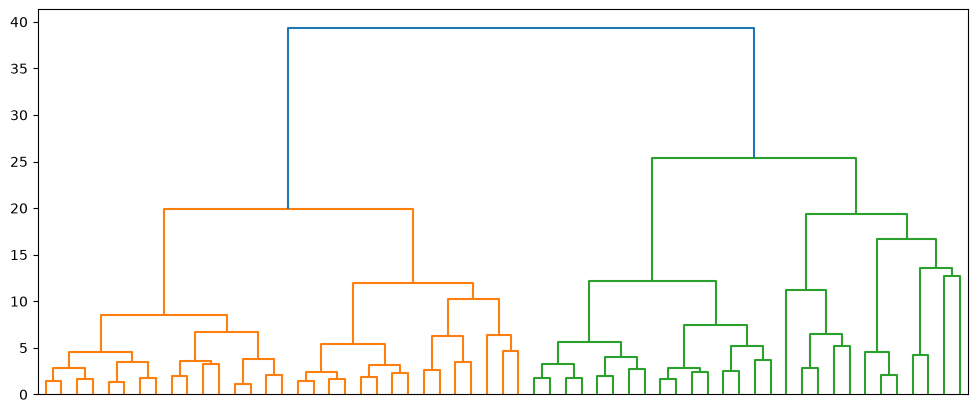

In [6]:
Z = linkage(X_scaled[:500], method="ward")
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="level", p=5, no_labels=True)
plt.show()

## Hierarchical Model

In [7]:
hier = AgglomerativeClustering(n_clusters=4, linkage="ward")
data["Hierarchical"] = hier.fit_predict(X_scaled)
data["Hierarchical"].value_counts()

Hierarchical
0    3222
1    1163
2     317
3     298
Name: count, dtype: int64

## DBSCAN Model

In [8]:
dbscan = DBSCAN(eps=0.8, min_samples=10)
data["DBSCAN"] = dbscan.fit_predict(X_scaled)
data["DBSCAN"].value_counts()

DBSCAN
 0    3427
 1    1086
-1     277
 2     202
 3       8
Name: count, dtype: int64

## Compare Silhouette Scores

In [9]:
scores = {}
for name in ["KMeans", "Hierarchical", "DBSCAN"]:
    labels = data[name]
    mask = labels != -1
    if labels[mask].nunique() > 1:
        scores[name] = round(silhouette_score(X_scaled[mask], labels[mask]), 3)
    else:
        scores[name] = np.nan

scores_df = pd.DataFrame(list(scores.items()), columns=["Algorithm", "Silhouette"])
scores_df

,Algorithm,Silhouette
0,KMeans,0.329
1,Hierarchical,0.373
2,DBSCAN,0.328


## Plot Clusters on PCA

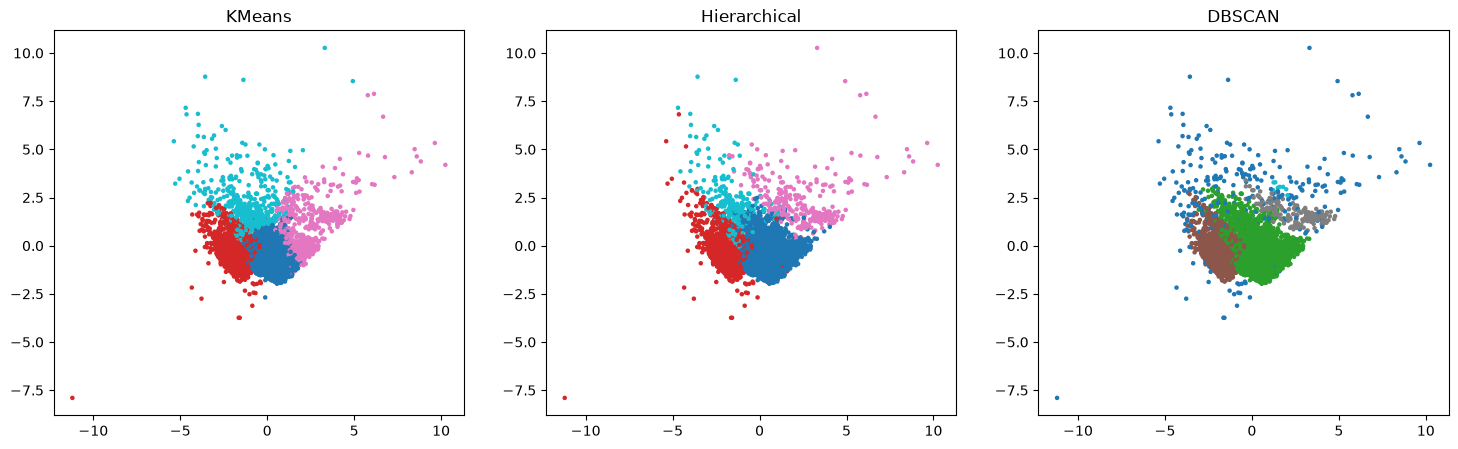

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for i, name in enumerate(["KMeans", "Hierarchical", "DBSCAN"]):
    ax[i].scatter(data["pca1"], data["pca2"], c=data[name], cmap="tab10", s=5)
    ax[i].set_title(name)
plt.show()

## Plot Clusters on t-SNE

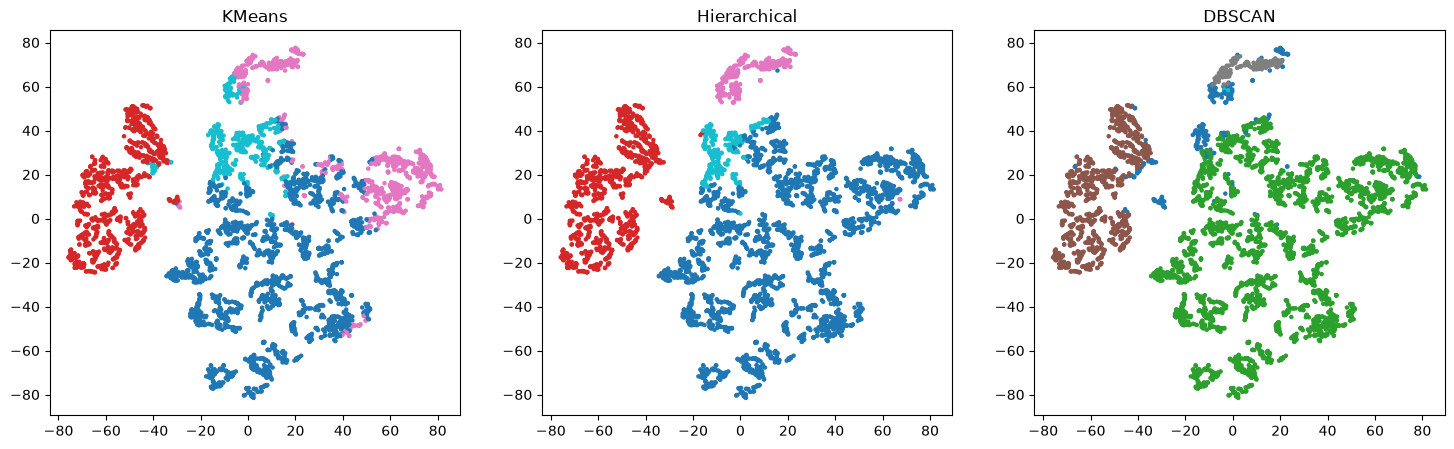

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for i, name in enumerate(["KMeans", "Hierarchical", "DBSCAN"]):
    ax[i].scatter(data["tsne1"], data["tsne2"], c=data[name], cmap="tab10", s=5)
    ax[i].set_title(name)
plt.show()

## Cluster Profile

In [12]:
data.groupby("KMeans")[features].mean().round(1)

,price,age,mileage,tax,mpg,engineSize
KMeans,,,,,,
0,15003.2,8.1,15102.1,145.6,54.4,1.4
1,11096.4,10.3,35943.7,20.8,67.5,1.5
2,33133.1,7.4,9070.2,154.4,44.2,2.3
3,11318.2,12.4,57885.3,165.2,50.1,2.0


## Save Results

In [13]:
data.to_csv("clusters.csv", index=False)
scores_df.to_csv("scores.csv", index=False)
joblib.dump(kmeans, "kmeans.pkl")
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']